# Clustering and outlier comparisons

**Purpose:** Compare three clustering methods and three outlier detectors; inspect assumptions and keep valid unusual encounters.

Requires the complete project folder and dependencies from `requirements.txt`; see README.md for local/Colab/Kaggle setup. Matching saved artifacts are reused. Use `force=True` in the phase cell to recompute. Outputs must remain visible when saving.

In [1]:
from pathlib import Path
import os, sys
for name in ['OMP_NUM_THREADS', 'OPENBLAS_NUM_THREADS', 'MKL_NUM_THREADS']:
    os.environ.setdefault(name, '2')
candidates = [Path.cwd(), *Path.cwd().parents,
              Path('/content/hospital-readmission'), Path('/kaggle/working/hospital-readmission')]
ROOT = next((p for p in candidates if (p / 'config.json').exists() and (p / 'readmission').is_dir()), None)
if ROOT is None:
    raise FileNotFoundError('Extract the full project and set the working directory to hospital-readmission first. See README.md.')
os.chdir(ROOT)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
import pandas as pd
from IPython.display import display, Image, JSON
from readmission.common import read_json
from readmission.pipeline import run_phase
pd.set_option('display.max_columns', 30)
print('Project:', ROOT.name)


Project: hospital-readmission


In [2]:
run_phase('unsupervised')

Phase data: reusing verified matching artifacts.


Phase unsupervised: reusing verified matching artifacts.


In [3]:
display(pd.read_csv(ROOT / 'artifacts/tables/clustering_metrics.csv'))

,algorithm,requested_clusters,actual_clusters,silhouette,calinski_harabasz,davies_bouldin,fit_seconds,encounters,warnings
0,MiniBatchKMeans,3,3,0.132652,8807.720839,2.211529,0.127700,59670,NaN
1,MiniBatchKMeans,5,5,0.155233,9296.828067,1.629456,0.030867,59670,NaN
2,MiniBatchKMeans,8,8,0.162309,9219.330803,1.467978,0.035248,59670,NaN
3,BIRCH,3,3,0.216221,6246.295290,1.866812,1.344817,59670,NaN
4,BIRCH,5,5,0.217891,5268.443284,1.665142,1.331302,59670,NaN
5,BIRCH,8,8,0.194327,3409.025102,1.842775,1.351497,59670,NaN
6,GaussianMixture,3,3,0.196849,4664.229641,3.367569,0.981253,59670,NaN
7,GaussianMixture,5,5,0.157188,6923.996615,1.742956,0.667234,59670,NaN
8,GaussianMixture,8,8,0.072935,4758.094536,2.397058,2.844241,59670,NaN


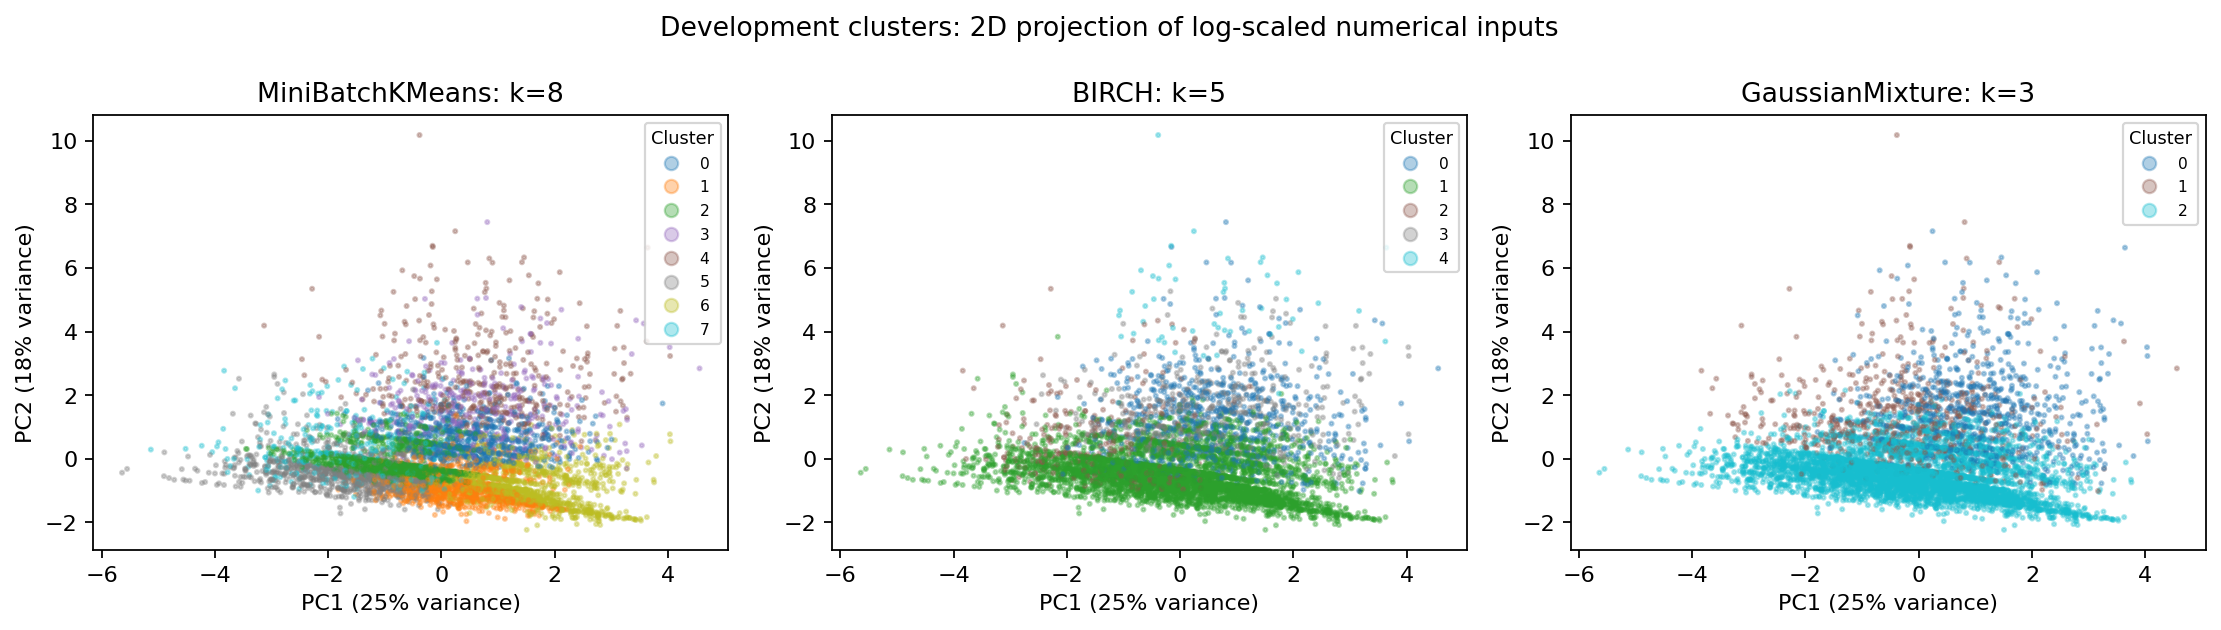

In [4]:
display(Image(filename=str(ROOT / 'artifacts/figures/clusters_pca.png'), width=1000))

In [5]:
display(pd.read_csv(ROOT / 'artifacts/tables/cluster_profiles.csv'))

,cluster,time_in_hospital,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,number_diagnoses,descriptive_readmission_rate,encounters,algorithm
0,0,4.954496,46.949470,0.694512,16.563706,0.149959,0.004890,2.344607,7.914154,0.186770,7362,MiniBatchKMeans
1,1,3.377997,41.016512,3.396193,17.827408,0.064682,0.034602,0.149874,7.401451,0.084350,9508,MiniBatchKMeans
2,2,2.890056,43.575975,0.192988,11.849018,0.074400,0.051377,0.127393,8.169400,0.090960,12379,MiniBatchKMeans
3,3,4.181773,43.215139,1.151145,17.070468,3.634462,0.182022,0.832918,8.117779,0.132719,4016,MiniBatchKMeans
4,4,4.367929,45.011936,0.956928,17.022314,0.612610,2.394914,2.229632,8.081474,0.201868,3854,MiniBatchKMeans
5,5,2.761473,40.689734,0.640217,9.689614,0.060145,0.043961,0.204348,4.209179,0.073551,8280,MiniBatchKMeans
6,6,8.362038,55.913696,2.029085,24.177930,0.074328,0.049805,0.250071,8.282388,0.122517,10521,MiniBatchKMeans
7,7,3.090133,2.823467,1.215467,12.257867,0.255200,0.101333,0.399467,7.124533,0.091200,3750,MiniBatchKMeans
8,0,4.336547,44.578420,1.253862,17.500309,2.286738,0.211840,0.976764,7.869237,0.134100,8091,BIRCH
9,1,4.441261,45.078280,1.373479,15.809236,0.009412,0.005041,0.442995,7.278919,0.103950,43242,BIRCH


In [6]:
display(pd.read_csv(ROOT / 'artifacts/tables/outlier_metrics.csv'))

,algorithm,sample_encounters,flagged,fraction,fit_seconds,readmission_rate_flagged,readmission_rate_unflagged
0,IsolationForest,12000,360,0.03,0.505118,0.244444,0.112371
1,LocalOutlierFactor,12000,360,0.03,0.602810,0.169444,0.114691
2,EllipticEnvelope,12000,360,0.03,1.732447,0.177778,0.114433


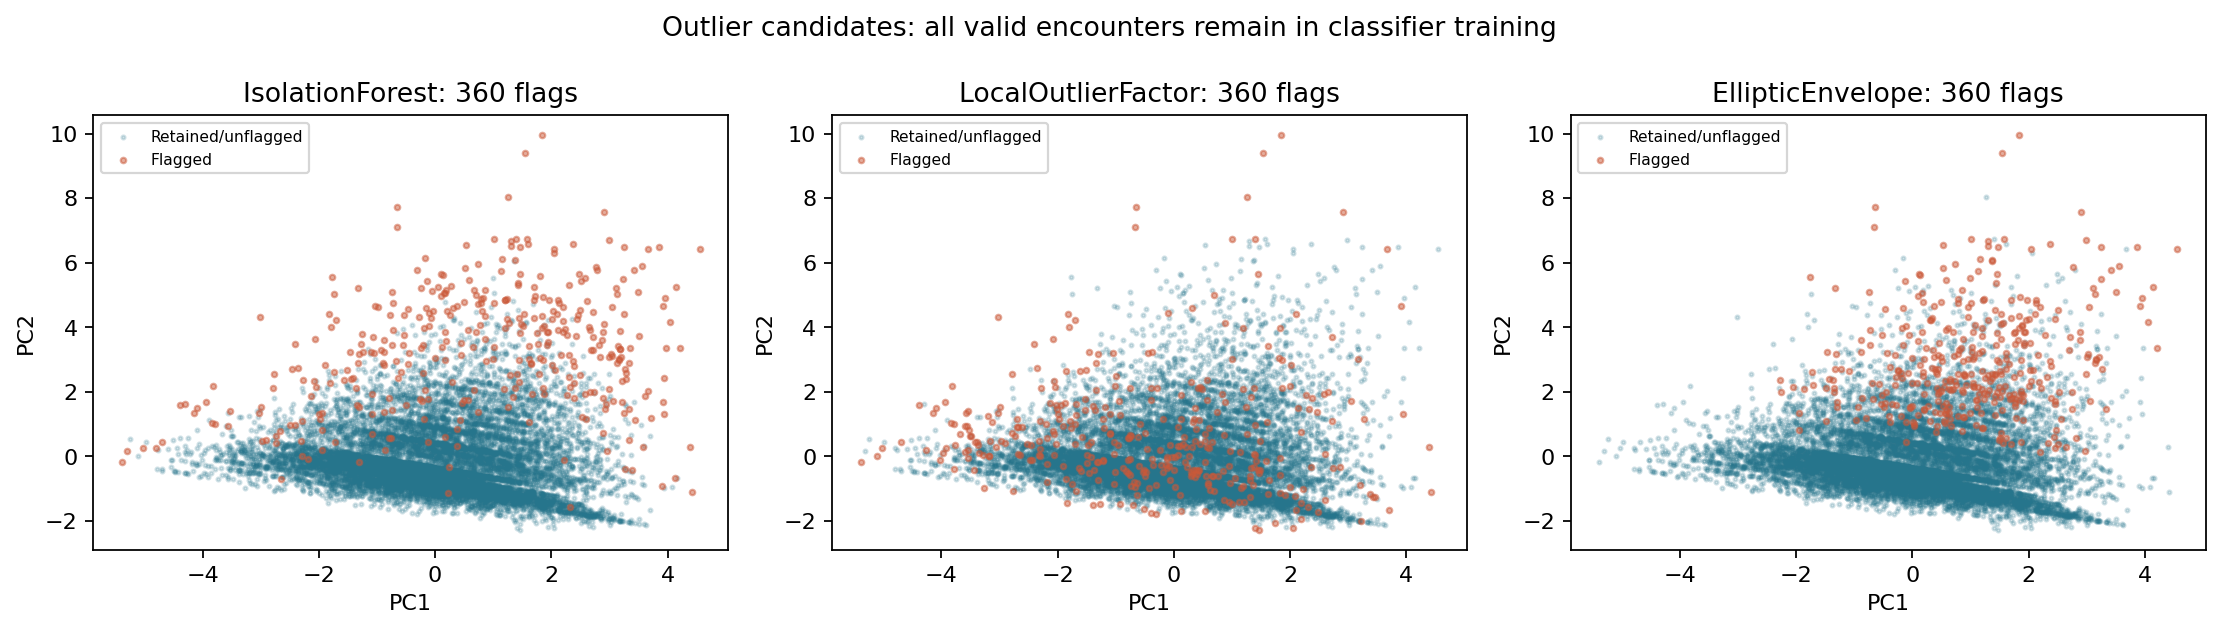

In [7]:
display(Image(filename=str(ROOT / 'artifacts/figures/outliers_pca.png'), width=1000))

In [8]:
display(pd.read_csv(ROOT / 'artifacts/tables/outlier_profiles.csv'))

,flagged,time_in_hospital,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,number_diagnoses,algorithm
0,False,4.0,44.0,1.0,15.0,0.0,0.0,0.0,8.0,IsolationForest
1,True,3.5,38.0,1.0,16.0,2.0,2.0,2.0,9.0,IsolationForest
2,False,4.0,44.0,1.0,15.0,0.0,0.0,0.0,8.0,LocalOutlierFactor
3,True,5.0,33.0,0.0,11.0,0.0,0.0,0.0,7.0,LocalOutlierFactor
4,False,4.0,44.0,1.0,15.0,0.0,0.0,0.0,8.0,EllipticEnvelope
5,True,3.0,47.0,0.0,16.0,4.0,0.0,1.0,9.0,EllipticEnvelope


In [9]:
display(pd.read_csv(ROOT / 'artifacts/tables/outlier_overlap.csv'))

,Unnamed: 0,IsolationForest,LocalOutlierFactor,EllipticEnvelope
0,IsolationForest,1.000000,0.137441,0.237113
1,LocalOutlierFactor,0.137441,1.000000,0.032999
2,EllipticEnvelope,0.237113,0.032999,1.000000


In [10]:
display(JSON(read_json('artifacts/unsupervised_design.json')))

<IPython.core.display.JSON object>

## Team interpretation prompts

Compare numerical utilization clusters, silhouette versus other indices, detector agreement, and the evidence for retaining flagged encounters.

Write your own report discussion after checking the evidence.